# Assignment 5 — Resume Matching: Experiments and Performance Analysis

This notebook explores the resume-matching pipeline and measures **retrieval quality** and **latency**.

## What this notebook measures

- **Precision@K:** proportion of the top K retrieved resumes that are relevant.
- **Recall@K:** proportion of all labeled relevant resumes found in the top K.
- **Hit Rate@K:** whether at least one relevant resume appears in the top K.
- **MRR (Mean Reciprocal Rank):** rewards finding the first relevant resume near the top.
- **Retrieval latency:** time taken for Cohere query embedding plus ChromaDB retrieval.
- **Optional end-to-end latency:** time for the full matcher, which may make multiple Cohere calls and use API credits.

**Important:** Retrieval accuracy needs ground-truth labels. You must review results and fill in `evaluation_queries_template.csv` with the resume filenames you consider relevant for each test query. The notebook will not invent accuracy values.

## 1. Setup

Place this notebook in the same project folder as `job_matcher.py`, `resume_rag.py`, `.env`, and `chroma_db/`. Run it from that folder.

If the resume collection is empty, first index the resumes using your app or run `resume_rag.py`. Do not share your `.env` file or API key.

In [1]:
from pathlib import Path
import os, sys, time, statistics, json
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "job_matcher.py").exists():
    raise FileNotFoundError(
        "Open this notebook from the Assignment 5 project folder, where job_matcher.py is located."
    )

os.chdir(PROJECT_DIR)
load_dotenv(PROJECT_DIR / ".env")

if not os.getenv("COHERE_API_KEY"):
    raise EnvironmentError("COHERE_API_KEY is missing. Add it to the project's .env file and restart the notebook kernel.")

import job_matcher as jm

print("Project folder:", PROJECT_DIR)
print("Embedding model:", jm.EMBED_MODEL)
print("Chroma collection:", jm.COLLECTION_NAME)
print("Indexed chunks:", jm.collection.count())

Project folder: C:\Users\shivam\OneDrive\Desktop\Assignment 5
Embedding model: embed-v4.0
Chroma collection: resume_collection
Indexed chunks: 144


## 2. Inspect the indexed resume data

This gives a quick view of how many chunks and distinct resumes are currently indexed.

In [2]:
all_items = jm.collection.get(include=["metadatas"])
metadatas = all_items.get("metadatas", []) or []
resume_paths = set()
for metadata in metadatas:
    metadata = metadata or {}
    path = metadata.get("resume_path") or metadata.get("filepath") or metadata.get("file_path")
    if path:
        resume_paths.add(str(path))

summary = {
    "indexed_chunks": jm.collection.count(),
    "distinct_resume_files": len(resume_paths),
    "embedding_model": jm.EMBED_MODEL,
    "chat_model": jm.CHAT_MODEL,
}
pd.DataFrame([summary])

,indexed_chunks,distinct_resume_files,embedding_model,chat_model
0,144,37,embed-v4.0,command-a-03-2025


## 3. Experiment with one query

Change the query and inspect the top retrieved resumes. This is an exploratory check, not an accuracy score.

In [3]:
sample_query = "Java backend developer with Spring Boot, REST APIs, SQL, and microservices experience"

def ranked_candidates(query):
    # Includes query embedding generation and ChromaDB retrieval.
    chunks = jm.retrieve_all_resume_chunks(query)
    candidates = jm.group_chunks_by_candidate(chunks)
    candidates.sort(key=lambda item: item.get("semantic_similarity", 0.0), reverse=True)
    return candidates

sample_results = ranked_candidates(sample_query)
preview = pd.DataFrame([
    {
        "rank": i + 1,
        "candidate": item.get("candidate_name"),
        "resume_file": Path(str(item.get("resume_path") or "")).name,
        "semantic_similarity": round(float(item.get("semantic_similarity", 0.0)), 4),
        "detected_skills": ", ".join(item.get("resume_skills", [])[:12]),
    }
    for i, item in enumerate(sample_results[:10])
])
preview

,rank,candidate,resume_file,semantic_similarity,detected_skills
0,1,Sudhanshu Singh,sudhanshu_resume_final.pdf,0.5687,"agile, aws, docker, git, github, java, jenkins..."
1,2,SHIVAM SINGH,shivamsinghresume.pdf,0.5254,"java, jenkins, spring, spring boot"
2,3,param resume,param_resume.pdf,0.4552,"agile, aws, docker, java, jenkins, kafka, kube..."
3,4,Jake Ryan,ryan resume.pdf,0.4476,"c++, css, docker, fastapi, flask, gcp, git, gi..."
4,5,Ryan Resume Summary,ryan resume summary.txt,0.4021,"c++, css, docker, fastapi, flask, gcp, git, gi..."
5,6,MICHELLE,lisbon-resume-template-creative.pdf,0.2883,"excel, html"
6,7,"John Huber, UX Designer",ux-designer-resume-example-5.pdf,0.2805,"communication, css, javascript"
7,8,Johanna Burton,customer-service-representative-resume-example...,0.2791,
8,9,Michelle Smith,account-manager-example-pdf.pdf,0.2723,
9,10,Kristen Connelly,sydney-resume-template-modern.pdf,0.2663,


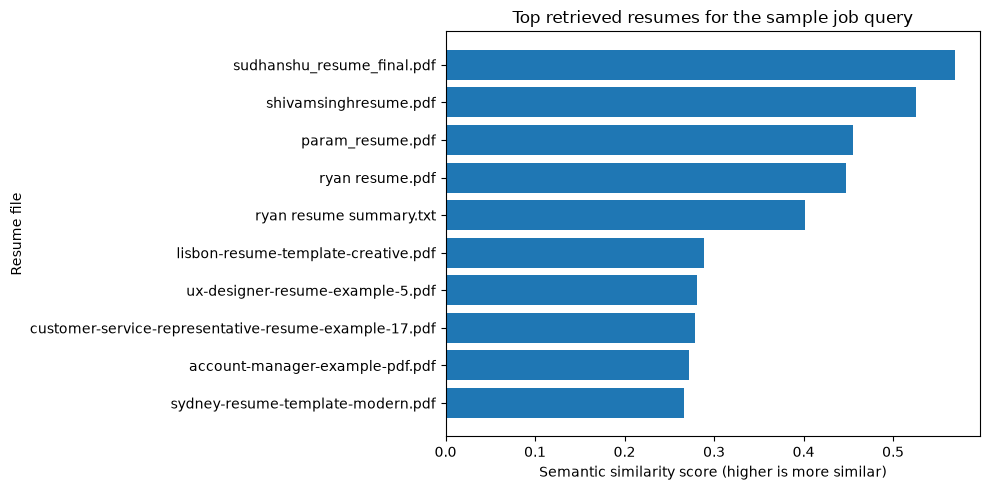

In [4]:
if not preview.empty:
    plot_data = preview.sort_values("semantic_similarity")
    plt.figure(figsize=(10, 5))
    plt.barh(plot_data["resume_file"], plot_data["semantic_similarity"])
    plt.xlabel("Semantic similarity score (higher is more similar)")
    plt.ylabel("Resume file")
    plt.title("Top retrieved resumes for the sample job query")
    plt.tight_layout()
    plt.show()

## 4. Prepare the relevance labels for retrieval accuracy

A retrieval system cannot be scored accurately without knowing which resumes are relevant to each query. Open `evaluation_queries_template.csv` in Excel or a text editor.

- Keep one job query per row.
- In `relevant_resume_files`, enter the relevant resume **filenames** separated by `|`.
- Use filenames that exist in your `resumes` folder / ChromaDB index.
- Judge relevance by reading the resume and query. It is fine for a query to have multiple relevant resumes.
- Save the completed file as `evaluation_queries.csv` in this project folder.

Example format: `sudhanshu_resume_final.pdf|shivamsinghresume.pdf`

Do not count an empty label row as zero relevant results; it is an unlabelled query and will be skipped.

In [5]:
template_path = PROJECT_DIR / "evaluation_queries_template.csv"
evaluation_path = PROJECT_DIR / "evaluation_queries.csv"

if not template_path.exists():
    template = pd.DataFrame([
        {"query": "Java backend developer with Spring Boot and SQL", "relevant_resume_files": ""},
        {"query": "Python developer with Django or Flask and REST APIs", "relevant_resume_files": ""},
        {"query": "Data analyst with SQL, Excel, and Power BI", "relevant_resume_files": ""},
        {"query": "Machine learning engineer with Python and scikit-learn", "relevant_resume_files": ""},
    ])
    template.to_csv(template_path, index=False)

print("Template:", template_path)
print("Evaluation labels file:", evaluation_path)
print("Fill the relevant_resume_files column, then save a copy as evaluation_queries.csv.")
pd.read_csv(template_path)

Template: C:\Users\shivam\OneDrive\Desktop\Assignment 5\evaluation_queries_template.csv
Evaluation labels file: C:\Users\shivam\OneDrive\Desktop\Assignment 5\evaluation_queries.csv
Fill the relevant_resume_files column, then save a copy as evaluation_queries.csv.


,query,relevant_resume_files
0,Java backend developer with Spring Boot and SQL,sudhanshu_resume_final|ShivamSinghResume|
1,Python developer with Django or Flask and REST...,pythonDev
2,"Data analyst with SQL, Excel, and Power BI",DataAnaylistResume
3,Machine learning engineer with Python and scik...,MachineLearningResume


## 5. Calculate retrieval accuracy metrics

The ranking below uses the project's semantic retrieval scores. The relevance labels are manually supplied in `evaluation_queries.csv`. Results are calculated only for rows with at least one labeled relevant filename.

In [6]:
def split_relevant_files(value):
    if pd.isna(value) or not str(value).strip():
        return set()
    return {Path(piece.strip()).name.casefold() for piece in str(value).split("|") if piece.strip()}

def metrics_at_k(ranked_filenames, relevant_filenames, k=5):
    top_k = [Path(name).name.casefold() for name in ranked_filenames[:k]]
    relevant = {Path(name).name.casefold() for name in relevant_filenames}
    hits = [name for name in top_k if name in relevant]
    first_rank = next((i + 1 for i, name in enumerate(top_k) if name in relevant), None)
    return {
        f"precision@{k}": len(hits) / k,
        f"recall@{k}": len(set(hits)) / len(relevant) if relevant else float("nan"),
        f"hit_rate@{k}": 1.0 if hits else 0.0,
        "reciprocal_rank": 1.0 / first_rank if first_rank else 0.0,
        "relevant_found": len(set(hits)),
        "known_relevant_total": len(relevant),
    }

if not evaluation_path.exists():
    print("No evaluation_queries.csv yet. Fill the template, save it as evaluation_queries.csv, then rerun this section.")
    accuracy_results = pd.DataFrame()
else:
    eval_df = pd.read_csv(evaluation_path)
    required_cols = {"query", "relevant_resume_files"}
    if not required_cols.issubset(eval_df.columns):
        raise ValueError("evaluation_queries.csv must contain: query, relevant_resume_files")

    rows = []
    for _, row in eval_df.iterrows():
        query = str(row["query"]).strip()
        relevant = split_relevant_files(row["relevant_resume_files"])
        if not query or not relevant:
            continue
        ranked = ranked_candidates(query)
        filenames = [Path(str(item.get("resume_path") or item.get("candidate_name") or "")).name
                     for item in ranked]
        m = metrics_at_k(filenames, relevant, k=5)
        rows.append({"query": query, **m})

    accuracy_results = pd.DataFrame(rows)
    if accuracy_results.empty:
        print("No labeled queries found. Add relevant filenames to evaluation_queries.csv.")
    else:
        display(accuracy_results)
        aggregate = accuracy_results[["precision@5", "recall@5", "hit_rate@5", "reciprocal_rank"]].mean().to_frame("mean_score")
        display(aggregate)

No evaluation_queries.csv yet. Fill the template, save it as evaluation_queries.csv, then rerun this section.


### How to report these metrics

Report the number of labeled queries and the average Precision@5, Recall@5, Hit Rate@5, and MRR. Include the date, dataset size, embedding model, and the fact that relevance labels were manually reviewed. Scores are meaningful only for the queries and labels you evaluated.

## 6. Measure retrieval latency

This benchmark measures the retrieval stage: generating a Cohere query embedding and querying ChromaDB. It does **not** include the full skill-verification and result-formatting pipeline.

In [7]:
latency_queries = [
    "Java backend developer with Spring Boot and SQL",
    "Python developer with Django and REST APIs",
    "Data analyst with SQL and Power BI",
]

REPEATS = 3  # Keep modest to limit API calls; increase only if needed.
latency_rows = []

for query in latency_queries:
    timings = []
    for repeat in range(REPEATS):
        start = time.perf_counter()
        _ = jm.retrieve_all_resume_chunks(query)
        timings.append((time.perf_counter() - start) * 1000)
    latency_rows.append({
        "query": query,
        "runs": len(timings),
        "mean_latency_ms": round(statistics.mean(timings), 2),
        "median_latency_ms": round(statistics.median(timings), 2),
        "min_latency_ms": round(min(timings), 2),
        "max_latency_ms": round(max(timings), 2),
    })

latency_results = pd.DataFrame(latency_rows)
latency_results

,query,runs,mean_latency_ms,median_latency_ms,min_latency_ms,max_latency_ms
0,Java backend developer with Spring Boot and SQL,3,394.75,402.70,376.94,404.59
1,Python developer with Django and REST APIs,3,485.45,380.45,371.96,703.93
2,Data analyst with SQL and Power BI,3,423.53,371.08,363.06,536.43


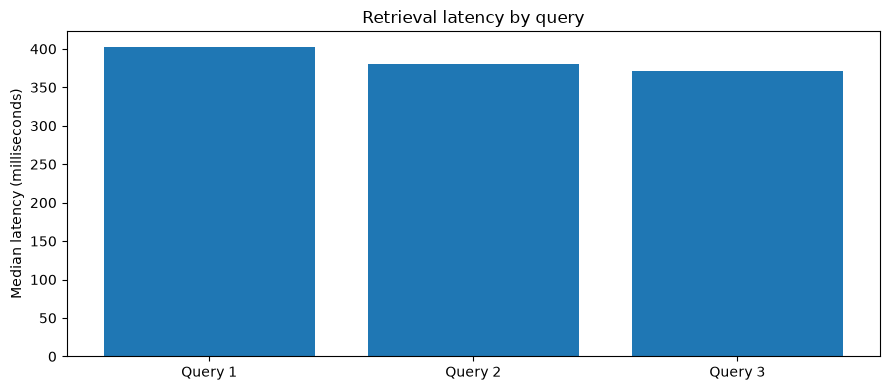

Overall median retrieval latency (ms): 380.45


In [8]:
if not latency_results.empty:
    plt.figure(figsize=(9, 4))
    plt.bar(range(len(latency_results)), latency_results["median_latency_ms"])
    plt.xticks(range(len(latency_results)), [f"Query {i+1}" for i in range(len(latency_results))])
    plt.ylabel("Median latency (milliseconds)")
    plt.title("Retrieval latency by query")
    plt.tight_layout()
    plt.show()

print("Overall median retrieval latency (ms):", round(float(latency_results["median_latency_ms"].median()), 2))

## 7. Optional: full end-to-end matcher latency

**This step can use Cohere chat API credits.** The matcher may evaluate skills for multiple candidates, so run it once for one representative query first. It is optional; retrieval latency above is the cheaper baseline.

In [9]:
RUN_FULL_MATCH_BENCHMARK = False  # Change to True only when you want to run the full matcher.
full_match_query = "Java backend developer with Spring Boot and SQL experience"

if RUN_FULL_MATCH_BENCHMARK:
    start = time.perf_counter()
    full_output = jm.match_candidates(
        job_description=full_match_query,
        mandatory_skills=[],
        min_experience=None,
        top_n=10,
    )
    elapsed_ms = (time.perf_counter() - start) * 1000
    print("Full matcher latency (ms):", round(elapsed_ms, 2))
    print("Indexed candidates:", full_output.get("total_candidates_indexed"))
    print("Returned matches:", len(full_output.get("matches", [])))
else:
    print("Skipped to avoid unexpected API usage. Set RUN_FULL_MATCH_BENCHMARK = True to run.")

Skipped to avoid unexpected API usage. Set RUN_FULL_MATCH_BENCHMARK = True to run.


## 8. Write-up template for the assignment

After running the notebook, use your actual output to complete this section in your report:

- **Dataset:** ___ resumes / ___ indexed chunks; ___ labeled evaluation queries.
- **Retrieval quality:** mean Precision@5 = ___; mean Recall@5 = ___; Hit Rate@5 = ___; MRR = ___.
- **Latency:** median query embedding + vector retrieval = ___ ms (report the median across test queries).
- **Environment:** CPU / RAM / OS = ___; embedding model = ___; date tested = ___.
- **Observation:** mention which query performed best/worst and inspect whether any relevant resume was ranked too low.
- **Limitations:** results depend on manually assigned relevance labels, resume extraction quality, API/network latency, and the size and composition of the resume collection.

Do not fill in numbers until the notebook has been run on your actual local index and labeled queries.